In [1]:
from collections import defaultdict
from itertools import combinations
import warnings

import matplotlib.pyplot as plt, numpy as np, pandas as pd, pywt, skfda
from memoria_icm.datos import cargar_datos
from memoria_icm.graficos import guardar_figura
from skfda import FDataGrid
from skfda.inference.anova import oneway_anova
from skfda.misc.operators import LinearDifferentialOperator
from skfda.misc.regularization import L2Regularization
from skfda.preprocessing.smoothing import BasisSmoother
from skfda.representation.basis import BSplineBasis, FourierBasis
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore")

colores_nivel = {"baja": "#2ca02c", "normal": "#1f77b4", "alta": "#d62728"}
orden_niveles = ["baja", "normal", "alta"]

nombres_grupos = {
    ("CC", "R"): "CC-Recuperación",
    ("CC", "E"): "CC-Exposición",
    ("LA", "R"): "LA-Recuperación",
    ("LA", "E"): "LA-Exposición"
}

etiquetas_variables = {
    "r": "$r(t)$",
    "dr": "$dr(t)$",
    "a": "$a(t)$",
    "v": "$v(t)$",
    "theta_r": "$\\theta_r(t)$",
    "v_angular": "$\\omega(t)$",
    "a_angular": "$\\alpha(t)$",
    "theta_v": "$\\theta_v(t)$",
    "curvatura": "$\\kappa(t)$"
}

#### 1. Funciones de representación funcional, agrupación e inferencia

In [2]:
def agrupar_datos_funcionales_salinidad(fdata_list, id_list, df_group):
  """Agrupa y concatena datos funcionales según el nivel de salinidad."""
  id_to_nivel = (
      df_group.drop_duplicates('id')[['id', 'nivel_salinidad']]
      .set_index('id')['nivel_salinidad']
  )
  group_dict = defaultdict(list)

  for i, larva_id in enumerate(id_list):
    if larva_id in id_to_nivel.index:
      group_dict[id_to_nivel.loc[larva_id]].append(fdata_list[i])

  return {
      nivel: skfda.concatenate(funcs)
      for nivel, funcs in group_dict.items()
      if len(funcs) > 2
  }


def anova_simple(grupos_funcionales, n_reps=1000):
  """Ejecuta ANOVA funcional de una vía por permutaciones."""
  if len(grupos_funcionales) < 2:
    print('Se necesitan al menos 2 grupos para ANOVA')
    return None

  grupo_names = list(sorted(grupos_funcionales.keys()))
  grupo_data = [grupos_funcionales[k] for k in grupo_names]

  print(f'Grupos para ANOVA: {grupo_names}')
  print(f'Tamaños: {[g.n_samples for g in grupo_data]}')

  try:
    res = oneway_anova(*grupo_data, n_reps=n_reps, random_state=42)
    stat, pval = (
        (res[0], res[1])
        if isinstance(res, tuple)
        else (res.statistic, res.pvalue)
    )
    return {
        'niveles': grupo_names,
        'n_por_nivel': [g.n_samples for g in grupo_data],
        'f_statistic': stat,
        'p_value': pval,
        'significativo': pval < 0.05,
        'grupos_funcionales': grupos_funcionales,
    }
  except Exception as e:
    print(f'Error en ANOVA: {e}')
    return None


def posthoc(grupos_funcionales, n_reps=1000, alpha=0.05):
  """Comparaciones post-hoc por pares con corrección de Bonferroni."""
  comparisons = list(combinations(sorted(grupos_funcionales.keys()), 2))
  if not comparisons:
    return None

  alpha_corrected = alpha / len(comparisons)
  print(
      f'POST HOC: {len(comparisons)} comparaciones por pares (α Bonferroni:'
      f' {alpha_corrected:.4f})'
  )

  resultados_posthoc = []
  for g1, g2 in comparisons:
    try:
      res = oneway_anova(
          grupos_funcionales[g1],
          grupos_funcionales[g2],
          n_reps=n_reps,
          random_state=42,
      )
      stat, pval = (
          (res[0], res[1])
          if isinstance(res, tuple)
          else (res.statistic, res.pvalue)
      )
      sig = pval < alpha_corrected
      resultados_posthoc.append({
          'grupos': f'{g1} vs {g2}',
          'p_value': pval,
          'p_value_corrected': alpha_corrected,
          'significativo': sig,
          'f_statistic': stat,
      })
      print(
          f"   {g1} vs {g2}: p={pval:.4f} ({'✅ SIG' if sig else '❌ NS'})"
      )
    except Exception as e:
      print(f'Error comparando {g1} vs {g2}: {e}')

  return resultados_posthoc


def crear_datos_funcionales_psplines(
    df_group, variable, n_basis, smoothing_parameter, min_puntos=10
):
  """Estandarización en dominio temporal común Tc y suavizado mediante P-splines."""
  trayectorias_validas = [
      (lid, g[['t', variable]].dropna())
      for lid, g in df_group.groupby('id')
      if pd.notna(lid) and len(g[['t', variable]].dropna()) >= min_puntos
  ]
  if not trayectorias_validas:
    return [], [], []

  t_min_comun = max(g['t'].min() for _, g in trayectorias_validas)
  t_max_comun = min(g['t'].max() for _, g in trayectorias_validas)
  if t_min_comun >= t_max_comun:
    print('No hay solapamiento temporal entre trayectorias')
    return [], [], []

  longitudes_en_dominio = [
      np.sum((g['t'] >= t_min_comun) & (g['t'] <= t_max_comun))
      for _, g in trayectorias_validas
      if np.sum((g['t'] >= t_min_comun) & (g['t'] <= t_max_comun)) >= min_puntos
  ]
  if not longitudes_en_dominio:
    print('No hay trayectorias con suficientes puntos en dominio común')
    return [], [], []

  n_interp = max(min(min(longitudes_en_dominio), 300), 50)
  common_t = np.linspace(t_min_comun, t_max_comun, n_interp)
  print(
      f'Dominio temporal truncado: {len(common_t)} puntos, de'
      f' {t_min_comun:.3f} a {t_max_comun:.3f} segundos'
  )

  #Instanciar base y suavizador una sola vez fuera del bucle
  basis = BSplineBasis(
      n_basis=n_basis, domain_range=(t_min_comun, t_max_comun)
  )
  smoother = BasisSmoother(
      basis=basis,
      regularization=L2Regularization(LinearDifferentialOperator(2)),
      smoothing_parameter=smoothing_parameter,
  )

  fdata_list, id_list = [], []
  for larva_id, g_clean in trayectorias_validas:
    g_dom = g_clean[
        (g_clean['t'] >= t_min_comun) & (g_clean['t'] <= t_max_comun)
    ]
    if len(g_dom) < min_puntos:
      continue
    interp_vals = np.interp(common_t, g_dom['t'].values, g_dom[variable].values)
    fgrid = FDataGrid(data_matrix=[interp_vals], grid_points=common_t)
    fdata_list.append(smoother.fit_transform(fgrid))
    id_list.append(larva_id)

  print(f'{len(fdata_list)} trayectorias procesadas')
  return fdata_list, id_list, common_t


def crear_datos_funcionales_raw(df_group, variable, min_puntos=10):
  """Datos funcionales SIN suavizado (interpolación lineal en grilla común)."""
  t_min, t_max = df_group['t'].min(), df_group['t'].max()
  n_interp = max(min(int(df_group.groupby('id').size().mean()), 500), 100)
  common_t = np.linspace(t_min, t_max, n_interp)
  print(
      f'Malla temporal: {len(common_t)} puntos de {t_min:.3f} a'
      f' {t_max:.3f} (Sin suavizado)'
  )

  fdata_list, id_list = [], []
  for larva_id, g in df_group.groupby('id'):
    g_clean = g[['t', variable]].dropna()
    if pd.isna(larva_id) or len(g_clean) < min_puntos:
      continue
    interp_vals = np.interp(
        common_t, g_clean['t'].values, g_clean[variable].values
    )
    fdata_list.append(
        FDataGrid(data_matrix=[interp_vals], grid_points=common_t)
    )
    id_list.append(larva_id)

  return fdata_list, id_list, common_t


def anova_fourier(df_group, variable, n_basis=30, min_puntos=10):
  """Suavizado con base de Fourier y ejecución de fANOVA."""
  t_min, t_max = df_group['t'].min(), df_group['t'].max()
  n_interp = max(min(int(df_group.groupby('id').size().mean()), 300), 50)
  common_t = np.linspace(t_min, t_max, n_interp)

  basis = FourierBasis(
      n_basis=n_basis, domain_range=(t_min, t_max), period=t_max - t_min
  )
  smoother = BasisSmoother(basis)

  fdata_list, id_list = [], []
  for larva_id, g in df_group.groupby('id'):
    g_clean = g[['t', variable]].dropna()
    if pd.isna(larva_id) or len(g_clean) < min_puntos:
      continue
    interp_vals = np.interp(
        common_t, g_clean['t'].values, g_clean[variable].values
    )
    fgrid = FDataGrid(data_matrix=[interp_vals], grid_points=common_t)
    fdata_list.append(smoother.fit_transform(fgrid))
    id_list.append(larva_id)

  if len(fdata_list) >= 6:
    grupos = agrupar_datos_funcionales_salinidad(fdata_list, id_list, df_group)
    if len(grupos) >= 2:
      return (
          anova_simple(grupos, n_reps=1000),
          fdata_list,
          id_list,
          common_t,
      )
  return None, [], [], []


def anova_wavelet(
    df_group, variable, wavelet='db4', levels=3, min_puntos=10
):
  """Filtrado multi-resolución con Wavelets y ejecución de fANOVA."""
  t_min, t_max = df_group['t'].min(), df_group['t'].max()
  n_interp = max(min(int(df_group.groupby('id').size().mean()), 256), 64)
  n_interp = 2 ** int(np.log2(n_interp))
  common_t = np.linspace(t_min, t_max, n_interp)

  fdata_list, id_list = [], []
  for larva_id, g in df_group.groupby('id'):
    g_clean = g[['t', variable]].dropna()
    if pd.isna(larva_id) or len(g_clean) < min_puntos:
      continue
    try:
      interp_vals = np.interp(
          common_t, g_clean['t'].values, g_clean[variable].values
      )
      coeffs = pywt.wavedec(interp_vals, wavelet, level=levels)
      if levels > 1:
        for i in range(min(2, levels)):
          coeffs[-(i + 1)] = np.zeros_like(coeffs[-(i + 1)])
      reconstructed = pywt.waverec(coeffs, wavelet)[: len(common_t)]
      fdata_list.append(
          FDataGrid(data_matrix=[reconstructed], grid_points=common_t)
      )
      id_list.append(larva_id)
    except Exception:
      continue

  if len(fdata_list) >= 6:
    grupos = agrupar_datos_funcionales_salinidad(fdata_list, id_list, df_group)
    if len(grupos) >= 2:
      return (
          anova_simple(grupos, n_reps=1000),
          fdata_list,
          id_list,
          common_t,
          wavelet,
      )
  return None, [], [], [], wavelet

#### 2. Optimización (exploratoria) de hiperparámetros ($n_{\text{basis}}$ y $\lambda$)

In [3]:
def optimizar_n_bases_global(df_completo, variable, n_basis_options=[15, 20, 25, 30, 35, 40, 45], cv_folds=3):
    trajectories_data = []
    for larva_id, g in df_completo.groupby('id'):
        g_clean = g[['t', variable]].dropna()
        if len(g_clean) >= 10:
            trajectories_data.append((larva_id, g_clean))
    
    print(f"Trayectorias válidas: {len(trajectories_data)}")
    
    if len(trajectories_data) < cv_folds:
        return 30
    
    t_min = df_completo['t'].min()
    t_max = df_completo['t'].max()
    n_interp = int(df_completo.groupby('id').size().mean())
    n_interp = max(min(n_interp, 300), 50)
    common_t = np.linspace(t_min, t_max, n_interp)
    
    best_n_basis = 30
    best_cv_score = float('inf')
    cv_results = {}
    
    for n_basis in n_basis_options:
        print(f"Probando n_basis={n_basis}...")
        
        kf = KFold(n_splits=cv_folds, shuffle=True, random_state=42)
        cv_scores = []
        
        for train_idx, test_idx in kf.split(trajectories_data):
            try:
                train_data = [trajectories_data[i] for i in train_idx]
                test_data = [trajectories_data[i] for i in test_idx]
                
                train_matrices = []
                for larva_id, g_clean in train_data:
                    interp_vals = np.interp(common_t, g_clean['t'].values, g_clean[variable].values)
                    train_matrices.append(interp_vals)
                
                if len(train_matrices) > 5:
                    train_fdata = FDataGrid(data_matrix=train_matrices, grid_points=common_t)
                    
                    # P-SPLINES COMPLETOS (B-splines + L2 regularization)
                    basis = BSplineBasis(n_basis=n_basis, domain_range=(common_t.min(), common_t.max()))
                    regularization = L2Regularization(LinearDifferentialOperator(2))
                    smoother = BasisSmoother(
                        basis=basis, 
                        regularization=regularization,
                        smoothing_parameter=1e-3
                    )
                    smoother.fit(train_fdata)
                                         
                    test_errors = []
                    for larva_id, g_clean in test_data:
                        interp_vals = np.interp(common_t, g_clean['t'].values, g_clean[variable].values)
                        test_fdata = FDataGrid(data_matrix=[interp_vals], grid_points=common_t)
                        
                        smoothed = smoother.transform(test_fdata)
                        mse = mean_squared_error(test_fdata.data_matrix[0], smoothed.data_matrix[0])
                        test_errors.append(mse)
                    
                if test_errors:
                    cv_scores.append(np.mean(test_errors))
                        
            except Exception as e:
                continue
        
        #Promedio de CV para este n_basis
        if cv_scores:
            avg_cv_score = np.mean(cv_scores)
            cv_results[n_basis] = avg_cv_score
            print(f"CV Score: {avg_cv_score:.6f}")
            
            if avg_cv_score < best_cv_score:
                best_cv_score = avg_cv_score
                best_n_basis = n_basis
    
    print(f"\n MEJOR n_basis GLOBAL: {best_n_basis} (Score: {best_cv_score:.6f})")
    print(f"Todos los scores: {cv_results}")
    
    return best_n_basis

def optimizar_lambda(df_group, variable, n_basis, lambda_options=[1e-5, 1e-4, 1e-3, 1e-2, 1e-1]):
    # OPTIMIZACIÓN DEL SMOOTHING PARAMETER (λ) para controlar spikes - VERSIÓN CON TRUNCAMIENTO
    
    print(f"🔧 Optimizando smoothing parameter λ...")
    print(f"   Probando λ: {lambda_options}")
    
    # Obtener trayectorias válidas
    trajectories_data = []
    for larva_id, g in df_group.groupby('id'):
        g_clean = g[['t', variable]].dropna()
        if len(g_clean) >= 10:
            trajectories_data.append((larva_id, g_clean))
    
    if len(trajectories_data) < 5:
        print(f"   ⚠️ Pocas trayectorias, usando λ=1e-3")
        return 1e-3
    
    # Determinar dominio común (intersección temporal)
    t_starts = [g_clean['t'].min() for _, g_clean in trajectories_data]
    t_ends = [g_clean['t'].max() for _, g_clean in trajectories_data]
    
    t_min_comun = max(t_starts)  # Max de los mínimos
    t_max_comun = min(t_ends)    # Min de los máximos
    
    if t_min_comun >= t_max_comun:
        print("   ⚠️ Sin solapamiento temporal, usando λ=1e-3")
        return 1e-3
    
    # Longitud mínima en dominio común
    longitudes_comun = []
    for _, g_clean in trajectories_data:
        mask = (g_clean['t'] >= t_min_comun) & (g_clean['t'] <= t_max_comun)
        longitudes_comun.append(np.sum(mask))
    
    n_interp = min(longitudes_comun)
    n_interp = max(min(n_interp, 300), 50)
    common_t = np.linspace(t_min_comun, t_max_comun, n_interp)
    
    best_lambda = 1e-3
    best_score = float('inf')
    
    for smoothing_param in lambda_options:
        try:
            matrices = []
            for larva_id, g_clean in trajectories_data:
                mask = (g_clean['t'] >= t_min_comun) & (g_clean['t'] <= t_max_comun)
                g_dominio = g_clean[mask]
                
                if len(g_dominio) >= 10:  # Suficientes puntos
                    interp_vals = np.interp(common_t, g_dominio['t'].values, g_dominio[variable].values)
                    matrices.append(interp_vals)
            
            if len(matrices) > 3:
                fdata = FDataGrid(data_matrix=matrices, grid_points=common_t)
                
                # P-splines con este λ
                basis = BSplineBasis(n_basis=n_basis, domain_range=(common_t.min(), common_t.max()))
                regularization = L2Regularization(LinearDifferentialOperator(2))
                smoother = BasisSmoother(
                    basis=basis, 
                    regularization=regularization,
                    smoothing_parameter=smoothing_param
                )
                smoothed = smoother.fit_transform(fdata)
                
                # Balance entre suavizado y fidelidad
                mse = np.mean([
                    mean_squared_error(fdata.data_matrix[i], smoothed.data_matrix[i])
                    for i in range(min(10, fdata.n_samples))  # Primeras 10
                ])
                
                # Rugosidad (derivadas altas)
                roughness = np.mean([
                        np.var(np.diff(smoothed.data_matrix[i].ravel(), n=2))
                        for i in range(min(5, smoothed.n_samples))
                        ])
                
                # Score combinado
                combined_score = mse + 0.1 * roughness
                
                print(f"   λ={smoothing_param:.0e}: MSE={mse:.6f}, Rough={roughness:.6f}, Score={combined_score:.6f}")
                
                if combined_score < best_score:
                    best_score = combined_score
                    best_lambda = smoothing_param
                
        except Exception as e:
            print(f"   λ={smoothing_param:.0e}: Error - {e}")
            continue
    
    print(f"   ✅ Mejor λ: {best_lambda:.0e} (Score: {best_score:.6f})")
    return best_lambda

def comparar_lambdas_suavizado(df_group, variable, n_basis=30):
    """
    Compara diferentes niveles de suavizado para encontrar el óptimo
    """
    print(f"COMPARANDO NIVELES DE SUAVIZADO para {variable}...")
    
    lambda_options = [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]  # Niveles de suavizado
    
    # Probar con diferentes λ
    for i, smoothing_param in enumerate(lambda_options):
        print(f"\nPrueba {i+1}/7: λ = {smoothing_param if smoothing_param > 0 else 'Sin suavizado'}")
        
        if smoothing_param == 0:
            # Datos originales sin suavizado
            fdata_list, id_list, common_t = crear_datos_funcionales_raw(df_group, variable)
            metodo = "Datos originales"
        else:
            # P-splines con este λ
            fdata_list, id_list, common_t = crear_datos_funcionales_psplines(
                df_group, variable, n_basis=n_basis, 
                smoothing_parameter=smoothing_param, min_puntos=10
            )
            metodo = f"P-splines λ={smoothing_param:.0e}"
        
        if len(fdata_list) >= 6:  # Suficientes datos
            # Agrupar por salinidad
            grupos_funcionales = agrupar_datos_funcionales_salinidad(fdata_list, id_list, df_group)
            
            if len(grupos_funcionales) >= 2:
                # ANOVA
                resultado = anova_simple(grupos_funcionales, n_reps=500)  # Menos reps para velocidad
                
                if resultado:
                    significativo = "✅ SIG" if resultado['significativo'] else "❌ NS"
                    print(f"   {metodo}: F={resultado['f_statistic']:.3f}, p={resultado['p_value']:.4f} {significativo}")
                else:
                    print(f"   {metodo}: Error en ANOVA")
            else:
                print(f"   {metodo}: Insuficientes grupos")
        else:
            print(f"   {metodo}: Insuficientes trayectorias")

#### 3. Definición del grupo de análisis

In [4]:
df, df_resumen = cargar_datos()

#INPUTS DE ANÁLISIS
especie_analizar = 'CC'
tratamiento_analizar = 'R'
variable_analizar = 'r'
lambda_grupo = 0.001
n_basis_grupo = 25

grupo_nombre = nombres_grupos.get(
    (especie_analizar, tratamiento_analizar),
    f'{especie_analizar}-{tratamiento_analizar}',
)
variable_nombre = etiquetas_variables.get(variable_analizar, variable_analizar)

# Filtrar el grupo y mapear IDs a nivel de salinidad una sola vez
df_grupo = df[
    (df['especie'] == especie_analizar)
    & (df['tratamiento'] == tratamiento_analizar)
].copy()
id_to_nivel = (
    df_grupo.drop_duplicates('id')[['id', 'nivel_salinidad']]
    .set_index('id')['nivel_salinidad']
)

print(
    f'ANALIZANDO -> Grupo: {grupo_nombre} ({len(df_grupo)} filas) | Variable:'
    f' {variable_analizar} ({variable_nombre})'
)

Datos cargados. Trackeo: (44324, 28), Resumen: (192, 42)
ANALIZANDO -> Grupo: CC-Recuperación (13403 filas) | Variable: r ($r(t)$)


In [5]:
# mejor_nbasis = optimizar_n_bases_global(df_grupo, variable_analizar)
# mejor_lambda = optimizar_lambda(df_grupo, variable_analizar, n_basis=n_basis_grupo)
# comparar_lambdas_suavizado(df_grupo, variable_analizar, n_basis=n_basis_grupo)

#### 4. Construcción de P-Splines con truncamiento, fANOVA principal

In [6]:
fdata_list, id_list, common_t_grid = crear_datos_funcionales_psplines(
    df,
    variable_analizar,
    n_basis=n_basis_grupo,
    smoothing_parameter=lambda_grupo,
)

grouped_data = agrupar_datos_funcionales_salinidad(fdata_list, id_list, df_grupo)
ultimo_resultado = anova_simple(grouped_data, n_reps=1000)

if ultimo_resultado:
  print(
      f"\nEstadístico F: {ultimo_resultado['f_statistic']:.6f} | p-valor ANOVA:"
      f" {ultimo_resultado['p_value']:.6f}"
  )
  print(
      "¡Diferencias significativas!"
      if ultimo_resultado["significativo"]
      else "No hay diferencias significativas"
  )

Dominio temporal truncado: 223 puntos, de 0.051 a 11.434 segundos
192 trayectorias procesadas
Grupos para ANOVA: ['alta', 'baja', 'normal']
Tamaños: [26, 17, 15]

Estadístico F: 73.013248 | p-valor ANOVA: 0.020000
¡Diferencias significativas!


#### 5. Visualización de datos originales vs. P-Splines

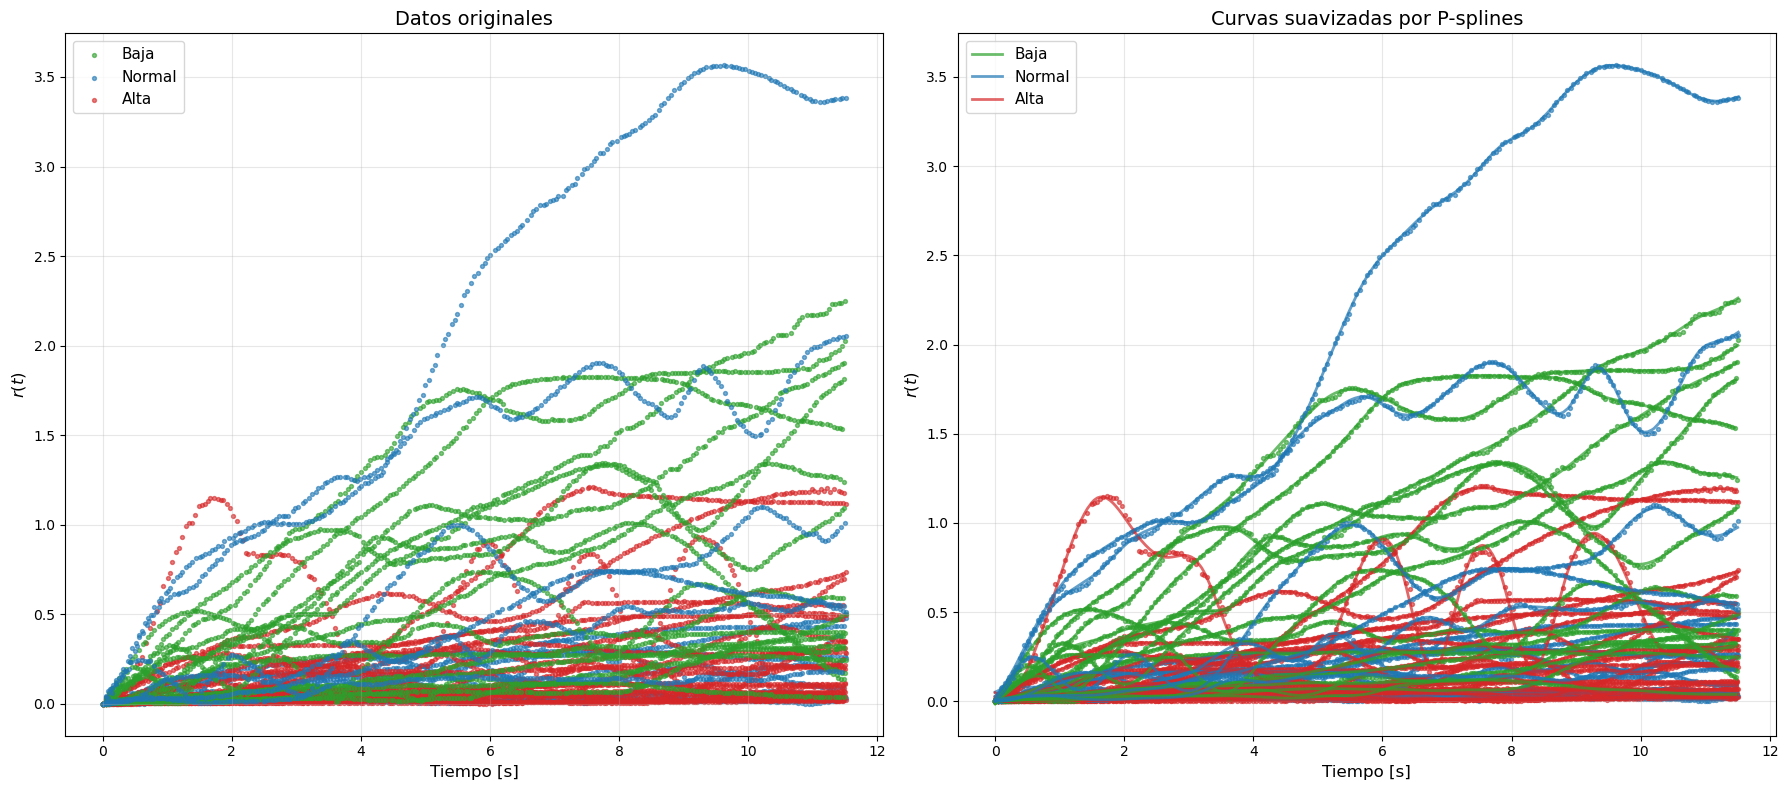

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

for i, larva_id in enumerate(id_list):
  if larva_id in id_to_nivel.index:
    g = df_grupo[df_grupo['id'] == larva_id].dropna(subset=[variable_analizar])
    nivel = id_to_nivel.loc[larva_id]
    if not g.empty and nivel in colores_nivel:
      t_vals, y_vals = g['t'].values, g[variable_analizar].values
      color = colores_nivel[nivel]

      # Panel 1: Datos originales
      ax1.scatter(
          t_vals, y_vals, color=color, alpha=0.6, s=8, label=nivel.capitalize()
      )

      # Panel 2: Puntos originales + Curva P-spline
      ax2.scatter(t_vals, y_vals, color=color, alpha=0.6, s=8)
      try:
        y_smooth = fdata_list[i](t_vals).ravel()
        ax2.plot(
            t_vals,
            y_smooth,
            color=color,
            alpha=0.7,
            linewidth=2,
            label=nivel.capitalize(),
        )
      except Exception:
        continue

for ax, titulo in zip(
    (ax1, ax2), ('Datos originales', 'Curvas suavizadas por P-splines')
):
  ax.set_title(titulo, fontsize=14)
  ax.set_xlabel('Tiempo [s]', fontsize=12)
  ax.set_ylabel(variable_nombre, fontsize=12)
  handles, labels = ax.get_legend_handles_labels()
  labels_map = {lab.lower(): (h, lab) for h, lab in zip(handles, labels)}
  ordered = [labels_map[n] for n in orden_niveles if n in labels_map]
  if ordered:
    ax.legend(
        [h for h, _ in ordered],
        [lab.capitalize() for _, lab in ordered],
        fontsize=11,
    )
  ax.grid(True, alpha=0.3)

#guardar_figura(f'{grupo_nombre}-{variable_analizar}', 'funcional')
plt.tight_layout()
plt.show()

#### 6. Visualización de curvas medias funcionales ($\pm$ SE)

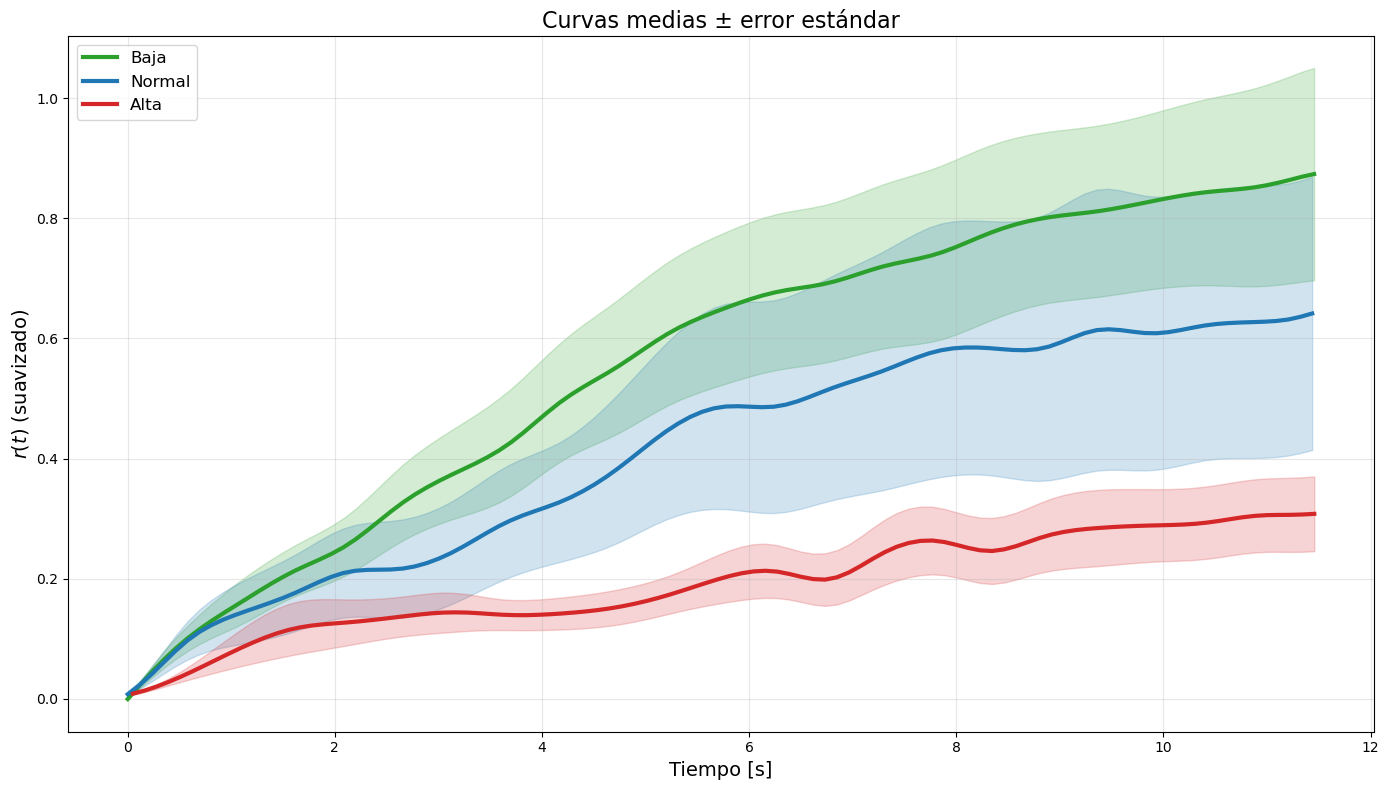

In [8]:
curvas_por_nivel = {'baja': [], 'normal': [], 'alta': []}
tiempos_por_nivel = {'baja': [], 'normal': [], 'alta': []}

for i, larva_id in enumerate(id_list):
  if larva_id in id_to_nivel.index and i < len(fdata_list):
    nivel = id_to_nivel.loc[larva_id]
    g = df_grupo[df_grupo['id'] == larva_id].dropna(subset=[variable_analizar])
    if len(g) >= 10:
      t_vals = g['t'].values
      try:
        curvas_por_nivel[nivel].append(fdata_list[i](t_vals).ravel())
        tiempos_por_nivel[nivel].append(t_vals)
      except Exception:
        continue

plt.figure(figsize=(14, 8))
for nivel in orden_niveles:
  curvas, tiempos = curvas_por_nivel[nivel], tiempos_por_nivel[nivel]
  if not curvas:
    continue

  t_min = max(min(t_vals) for t_vals in tiempos)
  t_max = min(max(t_vals) for t_vals in tiempos)
  t_common = np.linspace(t_min, t_max, 100)

  curvas_interp = [
      np.interp(
          t_common,
          t_v[(t_v >= t_min) & (t_v <= t_max)],
          c[(t_v >= t_min) & (t_v <= t_max)],
      )
      for c, t_v in zip(curvas, tiempos)
      if np.sum((t_v >= t_min) & (t_v <= t_max)) >= 3
  ]

  if curvas_interp:
    mat = np.array(curvas_interp)
    media = np.mean(mat, axis=0)
    se = np.std(mat, axis=0) / np.sqrt(len(mat))
    color = colores_nivel[nivel]
    plt.plot(t_common, media, color=color, linewidth=3, label=nivel.capitalize())
    plt.fill_between(t_common, media - se, media + se, color=color, alpha=0.2)

plt.title('Curvas medias ± error estándar', fontsize=16)
plt.xlabel('Tiempo [s]', fontsize=14)
plt.ylabel(f'{variable_nombre} (suavizado)', fontsize=14)
plt.legend(fontsize=12, loc='best')
plt.grid(True, alpha=0.3)
# guardar_figura(f'{grupo_nombre}-{variable_analizar}-MEDIAS', 'funcional')
plt.tight_layout()
plt.show()

#### 7. Comparación de bases funcionales

In [9]:
# 1. fANOVA sin suavizado (datos originales)
fdata_raw, id_raw, common_t_raw = crear_datos_funcionales_raw(
    df_grupo, variable_analizar
)
resultado_raw = None

if len(fdata_raw) >= 6:
  grupos_raw = agrupar_datos_funcionales_salinidad(fdata_raw, id_raw, df_grupo)
  if len(grupos_raw) >= 2:
    resultado_raw = anova_simple(grupos_raw, n_reps=1000)
    if resultado_raw:
      print("RESULTADO SIN SUAVIZADO:")
      print(f"F-statistic: {resultado_raw['f_statistic']:.4f}")
      print(f"p-value: {resultado_raw['p_value']:.6f}")
      print(
          "SIGNIFICATIVO"
          if resultado_raw["significativo"]
          else "NO SIGNIFICATIVO"
      )

# 2. fANOVA con base Fourier
resultado_fourier, fdata_fourier, id_fourier, common_t_fourier = (
    anova_fourier(df_grupo, variable_analizar, n_basis=25)
)

if resultado_fourier:
  print("\nRESULTADO FOURIER:")
  print(f"F-statistic: {resultado_fourier['f_statistic']:.4f}")
  print(f"p-value: {resultado_fourier['p_value']:.6f}")
  print(
      "SIGNIFICATIVO"
      if resultado_fourier["significativo"]
      else "NO SIGNIFICATIVO"
  )

# 3. fANOVA con base Wavelet
wavelets_options = [
    {"name": "db4", "levels": 3},
    {"name": "db8", "levels": 3},
    {"name": "haar", "levels": 3},
    {"name": "coif2", "levels": 3},
]

resultados_wavelets = {}
for w_opt in wavelets_options:
  try:
    resultado_w, fdata_w, id_w, common_t_w, wavelet_usado = (
        anova_wavelet(
            df_grupo,
            variable_analizar,
            wavelet=w_opt["name"],
            levels=w_opt["levels"],
        )
    )
    if resultado_w:
      resultados_wavelets[w_opt["name"]] = {
          "resultado": resultado_w,
          "fdata": fdata_w,
          "ids": id_w,
          "common_t": common_t_w,
          "wavelet": wavelet_usado,
      }
      print(f"\nRESULTADO WAVELET ({w_opt['name'].upper()}):")
      print(f"F-statistic: {resultado_w['f_statistic']:.4f}")
      print(f"p-value: {resultado_w['p_value']:.6f}")
      print(
          "SIGNIFICATIVO"
          if resultado_w["significativo"]
          else "NO SIGNIFICATIVO"
      )
  except Exception as e:
    print(f"Error procesando {w_opt['name']}: {e}")

# Resumen comparativo
if resultados_wavelets:
  if "ultimo_resultado" in locals() and ultimo_resultado:
    print(
        f"\n🔧 P-SPLINES (referencia):"
        f" F={ultimo_resultado['f_statistic']:.4f},"
        f" p={ultimo_resultado['p_value']:.6f}"
        f" ({'✅ SIG' if ultimo_resultado['significativo'] else '❌ NS'})"
    )
  print("\n🌊 WAVELETS:")
  for name, data in resultados_wavelets.items():
    r = data["resultado"]
    print(
        f"   {name.upper()}: F={r['f_statistic']:.4f}, p={r['p_value']:.6f}"
        f" ({'✅ SIG' if r['significativo'] else '❌ NS'})"
    )

Malla temporal: 231 puntos de 0.000 a 11.515 (Sin suavizado)
Grupos para ANOVA: ['alta', 'baja', 'normal']
Tamaños: [26, 17, 15]
RESULTADO SIN SUAVIZADO:
F-statistic: 74.0071
p-value: 0.020000
SIGNIFICATIVO
Grupos para ANOVA: ['alta', 'baja', 'normal']
Tamaños: [26, 17, 15]

RESULTADO FOURIER:
F-statistic: 73.3990
p-value: 0.020000
SIGNIFICATIVO
Grupos para ANOVA: ['alta', 'baja', 'normal']
Tamaños: [26, 17, 15]

RESULTADO WAVELET (DB4):
F-statistic: 74.0033
p-value: 0.015000
SIGNIFICATIVO
Grupos para ANOVA: ['alta', 'baja', 'normal']
Tamaños: [26, 17, 15]

RESULTADO WAVELET (DB8):
F-statistic: 73.9979
p-value: 0.015000
SIGNIFICATIVO
Grupos para ANOVA: ['alta', 'baja', 'normal']
Tamaños: [26, 17, 15]

RESULTADO WAVELET (HAAR):
F-statistic: 73.8004
p-value: 0.015000
SIGNIFICATIVO
Grupos para ANOVA: ['alta', 'baja', 'normal']
Tamaños: [26, 17, 15]

RESULTADO WAVELET (COIF2):
F-statistic: 74.0108
p-value: 0.015000
SIGNIFICATIVO

🔧 P-SPLINES (referencia): F=73.0132, p=0.020000 (✅ SIG)

🌊 W

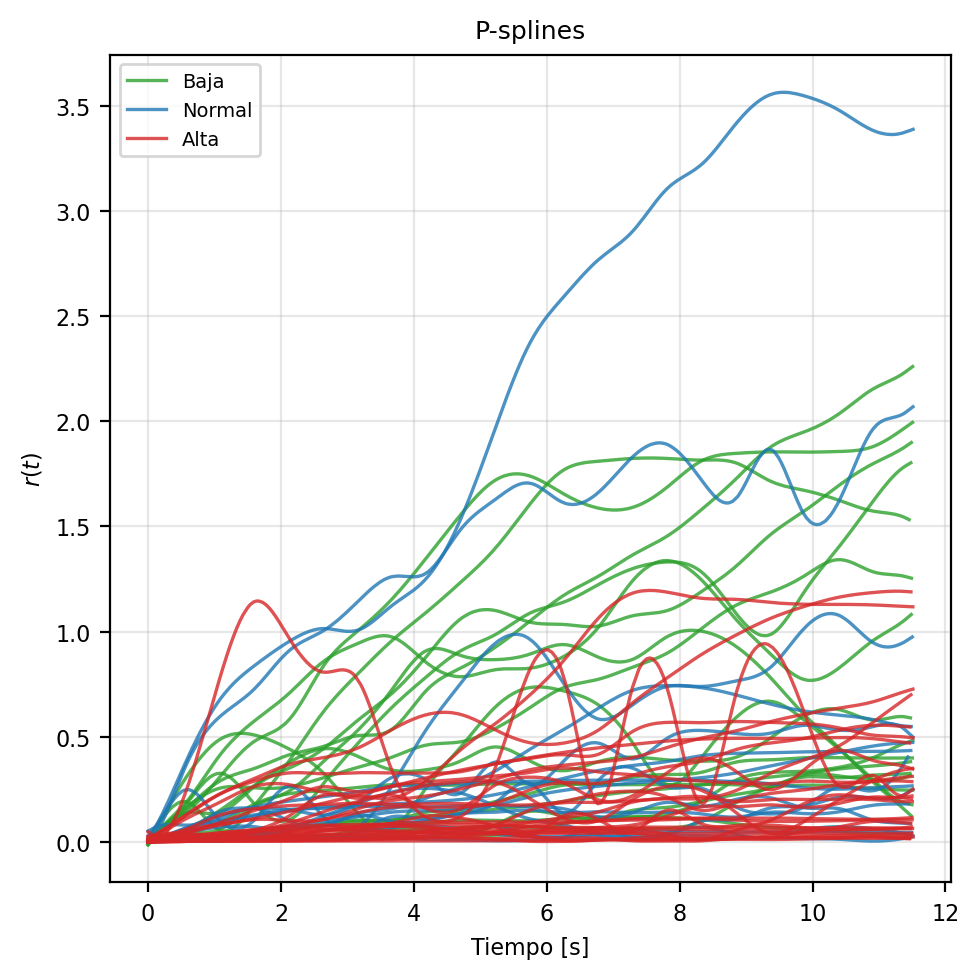

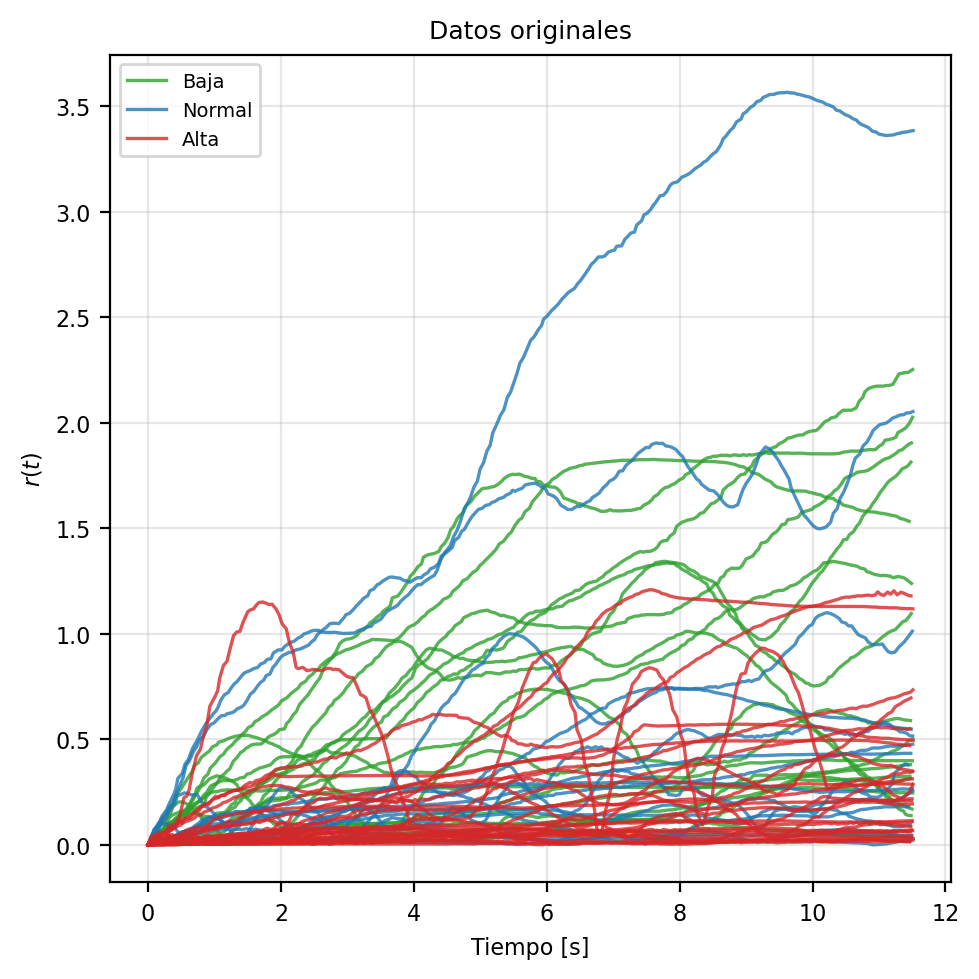

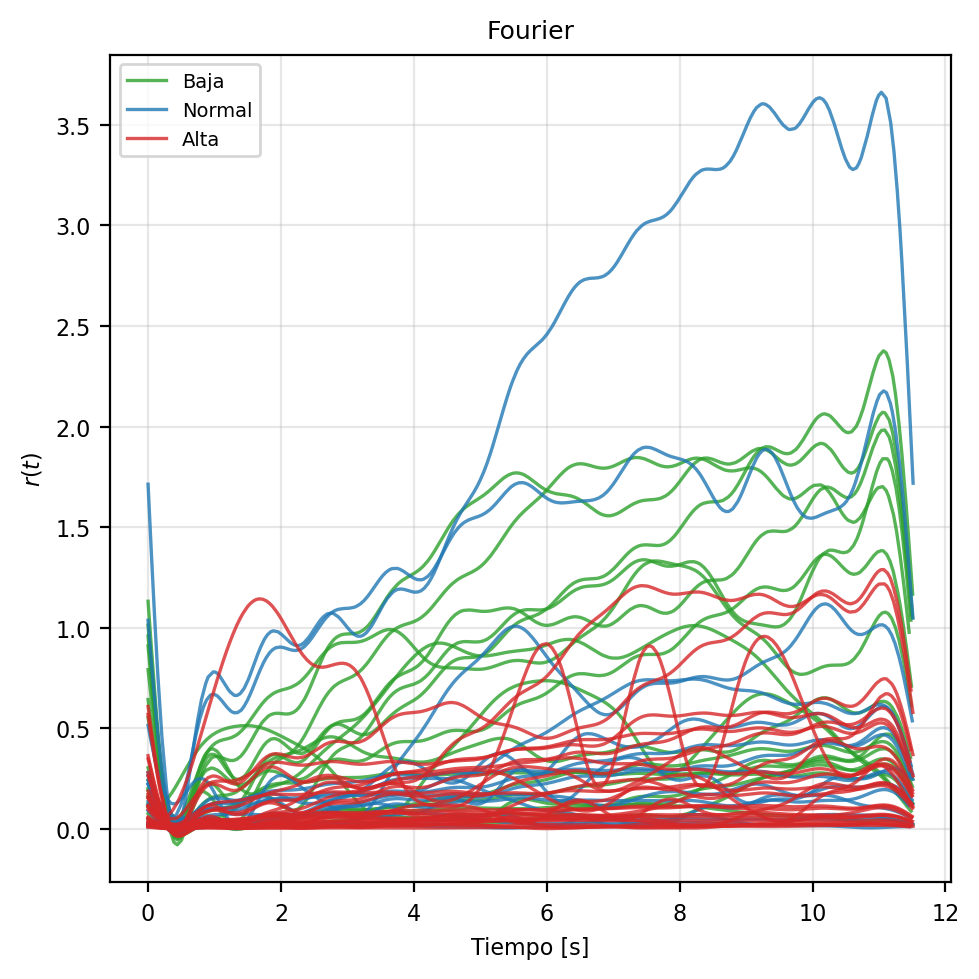

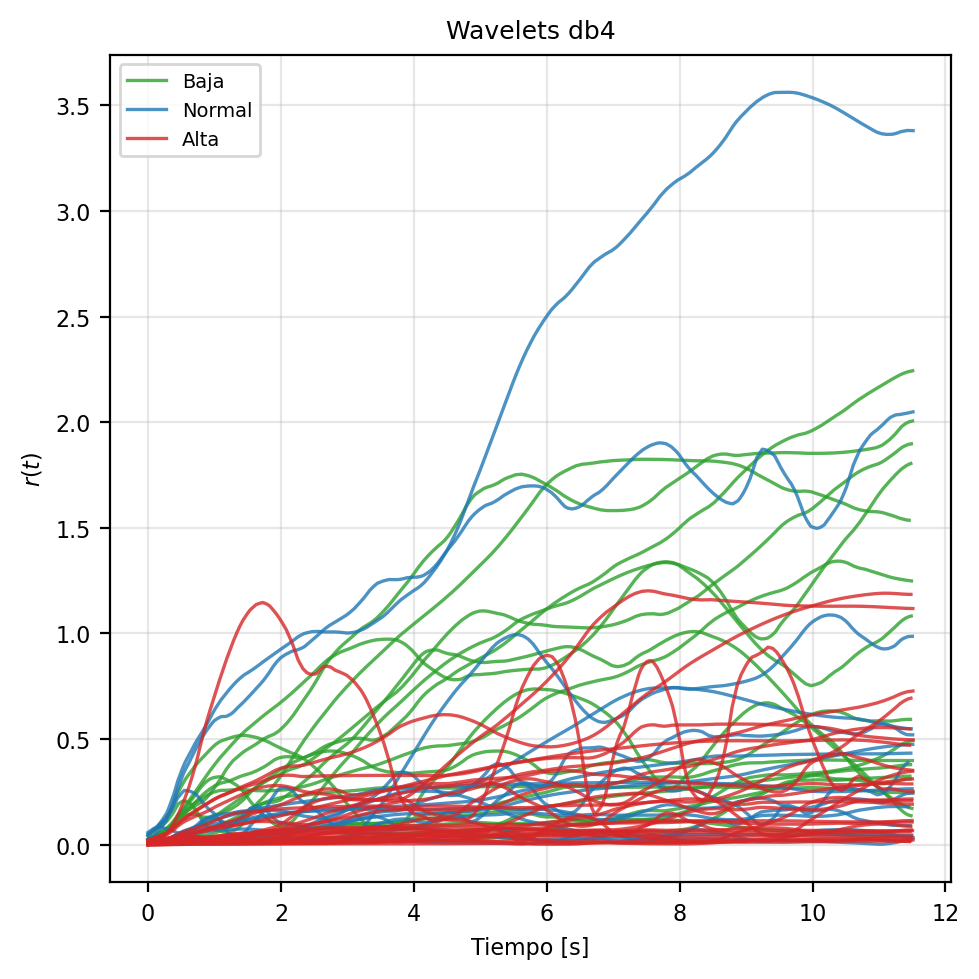

In [10]:
# Reutiliza directamente las representaciones ya calculadas sin repetir los fANOVA
mejor_w = list(resultados_wavelets.keys())[0] if resultados_wavelets else None

catalogo_bases = {
    'psplines': ('P-splines', fdata_list, id_list),
    'raw': ('Datos originales', fdata_raw, id_raw),
    'fourier': ('Fourier', fdata_fourier, id_fourier),
    'wavelet': (
        f'Wavelets {mejor_w}',
        resultados_wavelets[mejor_w]['fdata'] if mejor_w else None,
        resultados_wavelets[mejor_w]['ids'] if mejor_w else None,
    ),
}

for clave_base, (metodo_nombre, fdata_viz, ids_viz) in catalogo_bases.items():
  if not fdata_viz or not ids_viz:
    continue

  fig, ax = plt.subplots(figsize=(5, 5), dpi=200)
  handles, labels = [], []

  for nivel in orden_niveles:
    ids_del_nivel = [
        lid
        for lid in ids_viz
        if lid in id_to_nivel.index and id_to_nivel.loc[lid] == nivel
    ]
    if not ids_del_nivel:
      continue

    for i, larva_id in enumerate(ids_viz):
      if larva_id in ids_del_nivel:
        g = df_grupo[df_grupo['id'] == larva_id].dropna(
            subset=[variable_analizar]
        )
        if g.empty:
          continue
        t_vals = g['t'].values
        y_vals = (
            g[variable_analizar].values
            if clave_base == 'raw'
            else fdata_viz[i](t_vals).ravel()
        )
        line = ax.plot(
            t_vals,
            y_vals,
            color=colores_nivel[nivel],
            alpha=0.8,
            linewidth=1.2,
        )
        if larva_id == ids_del_nivel[0]:
          handles.append(line[0])
          labels.append(nivel.capitalize())

  ax.set_title(metodo_nombre, fontsize=9)
  ax.set_xlabel('Tiempo [s]', fontsize=8)
  ax.set_ylabel(variable_nombre, fontsize=8)
  ax.tick_params(axis='both', which='major', labelsize=8)
  ax.grid(True, alpha=0.3)
  if handles:
    ax.legend(handles, labels, fontsize=7, loc='best')

  plt.tight_layout()
  # guardar_figura(f'{grupo_nombre}-{variable_analizar}-{clave_base.upper()}', 'funcional')
  plt.show()

#### 8. Análisis post-hoc funcional con corrección de Bonferroni

In [11]:
if 'grouped_data' in locals() and len(grouped_data) >= 2:
  print(f'🔬 Análisis post-hoc funcional por pares ({grupo_nombre}):')
  resultados_posthoc = posthoc(
      grouped_data, n_reps=1000, alpha=0.05
  )

  if resultados_posthoc:
    print('\nResumen de comparaciones por pares (Bonferroni):')
    for res in resultados_posthoc:
      status = (
          '✅ Significativo' if res['significativo'] else '❌ No significativo'
      )
      print(
          f"   • {res['grupos']:<18} | F={res['f_statistic']:.4f} |"
          f" p={res['p_value']:.4f} (α_corr={res['p_value_corrected']:.4f}) ->"
          f' {status}'
      )
else:
  print(
      '❌ Ejecuta primero el análisis principal para tener grouped_data'
      ' disponible.'
  )

🔬 Análisis post-hoc funcional por pares (CC-Recuperación):
POST HOC: 3 comparaciones por pares (α Bonferroni: 0.0167)
   alta vs baja: p=0.0010 (✅ SIG)
   alta vs normal: p=0.0720 (❌ NS)
   baja vs normal: p=0.4190 (❌ NS)

Resumen de comparaciones por pares (Bonferroni):
   • alta vs baja       | F=49.6222 | p=0.0010 (α_corr=0.0167) -> ✅ Significativo
   • alta vs normal     | F=18.2894 | p=0.0720 (α_corr=0.0167) -> ❌ No significativo
   • baja vs normal     | F=5.1017 | p=0.4190 (α_corr=0.0167) -> ❌ No significativo
